In [1]:
%pip install -q torch torchvision diffusers transformers accelerate safetensors
%pip install -q opencv-python pillow requests "rembg[gpu]" onnxruntime matplotlib pandas

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


ERROR: Could not install packages due to an OSError: [WinError 5] Access is denied: 'C:\\Users\\admin\\gpu_env\\Lib\\site-packages\\onnxruntime\\capi\\onnxruntime_providers_shared.dll'
Check the permissions.



In [4]:
from pathlib import Path
from PIL import Image
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import torch

BASE_DIR = Path("tshirt_dataset")
SOURCE_DIR = BASE_DIR / "selected"
OUTPUT_DIR = Path("generated_designs")

IMAGE_SIZE = 768

images = []
image_metadata = []

for set_id in range(1, 6):
    for view in ["front", "back"]:

        image_path = SOURCE_DIR / f"set_{set_id}" / f"{view}.jpg"

        if not image_path.exists():
            raise FileNotFoundError(f"Missing image: {image_path}")

        image = Image.open(image_path).convert("RGB")
        image.thumbnail((IMAGE_SIZE, IMAGE_SIZE))

        canvas = Image.new(
            "RGB", (IMAGE_SIZE, IMAGE_SIZE), (245, 245, 245)
        )

        x = (IMAGE_SIZE - image.width) // 2
        y = (IMAGE_SIZE - image.height) // 2
        canvas.paste(image, (x, y))

        images.append(canvas)

        image_metadata.append({
            "image_index": len(images) - 1,
            "set_id": set_id,
            "view": view,
            "path": str(image_path)
        })

assert len(images) == 10

print("Images loaded:", len(images))
print("Image size:", images[0].size)
print("Order: Set 1 front, Set 1 back, ..., Set 5 back")

Images loaded: 10
Image size: (768, 768)
Order: Set 1 front, Set 1 back, ..., Set 5 back


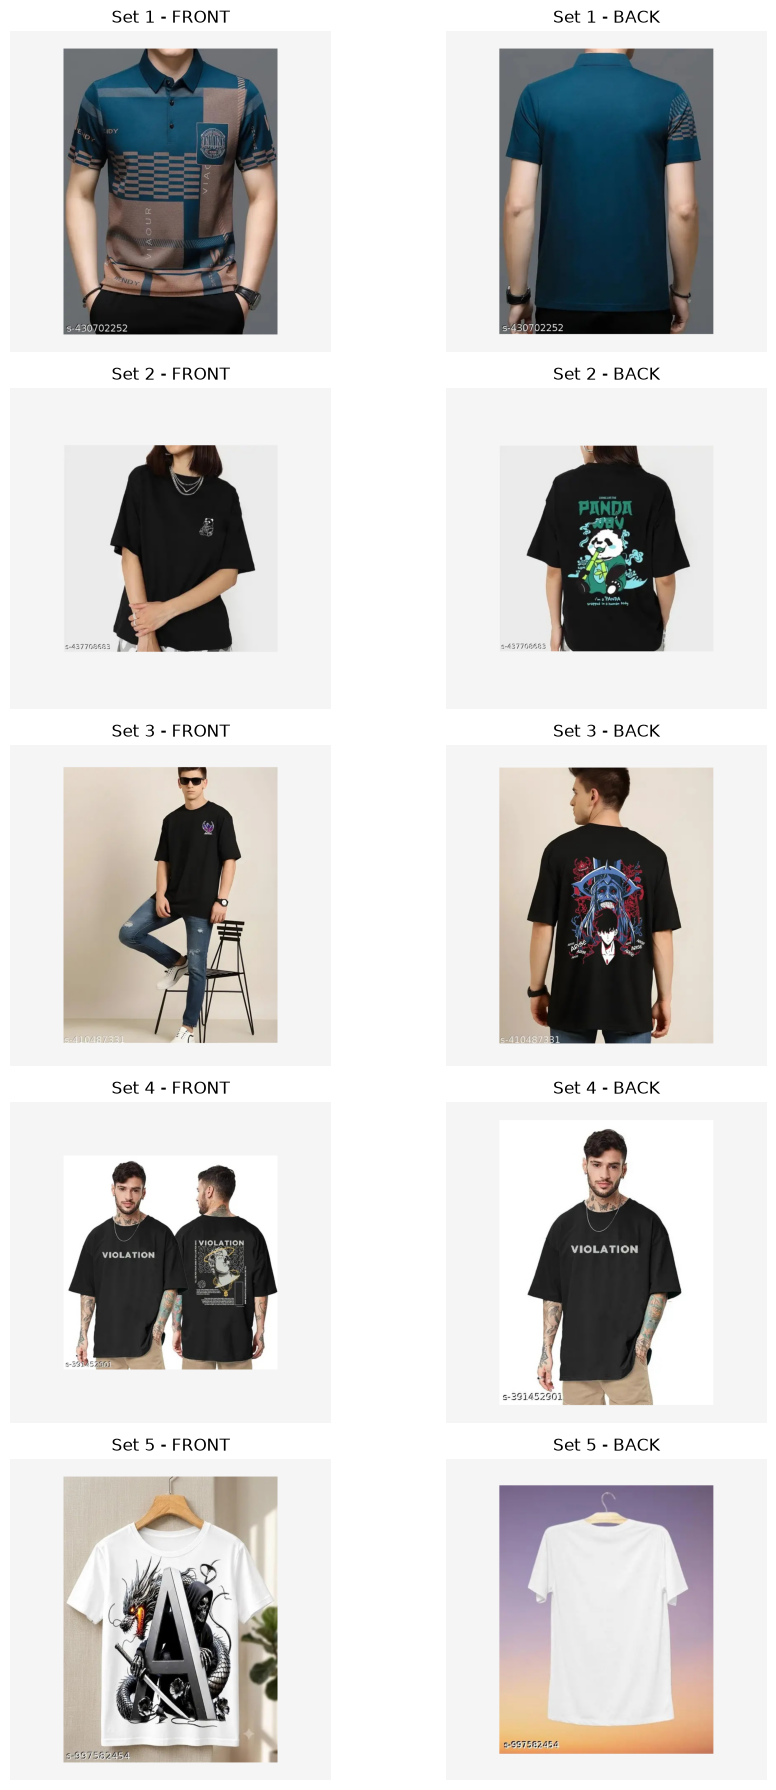

In [5]:
fig, axes = plt.subplots(5, 2, figsize=(10, 18))

for index, ax in enumerate(axes.flat):
    ax.imshow(images[index])
    ax.set_title(
        f"Set {image_metadata[index]['set_id']} - "
        f"{image_metadata[index]['view'].upper()}"
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

In [6]:
from rembg import remove, new_session

rembg_session = new_session("u2net")
masks = []

for index, image in enumerate(images):

    mask_image = remove(
        image,
        session=rembg_session,
        only_mask=True
    ).convert("L")

    mask_image = mask_image.resize((IMAGE_SIZE, IMAGE_SIZE))
    mask_array = np.array(mask_image)

    mask_array = np.where(
        mask_array > 127, 255, 0
    ).astype(np.uint8)

    mask_array = cv2.medianBlur(mask_array, 5)

    masks.append(Image.fromarray(mask_array))

    print(
        f"Mask {index + 1}/10 created: "
        f"Set {image_metadata[index]['set_id']} "
        f"{image_metadata[index]['view']}"
    )

C:\Users\admin\gpu_env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
C:\Users\admin\gpu_env\Lib\site-packages\rembg\session_factory.py:56: RuntimeWarning: CUDAExecutionProvider was requested but the session is running on CPU. onnxruntime could not load the provider, usually because the matching CUDA/cuDNN runtime libraries are missing or are a different major version than the onnxruntime-gpu build. Inference will be slow. See the onnxruntime stderr output above for the specific library that failed to load.
  return session_class(model_name, sess_opts, *args, **kwargs)


Mask 1/10 created: Set 1 front
Mask 2/10 created: Set 1 back
Mask 3/10 created: Set 2 front
Mask 4/10 created: Set 2 back
Mask 5/10 created: Set 3 front
Mask 6/10 created: Set 3 back
Mask 7/10 created: Set 4 front
Mask 8/10 created: Set 4 back
Mask 9/10 created: Set 5 front
Mask 10/10 created: Set 5 back


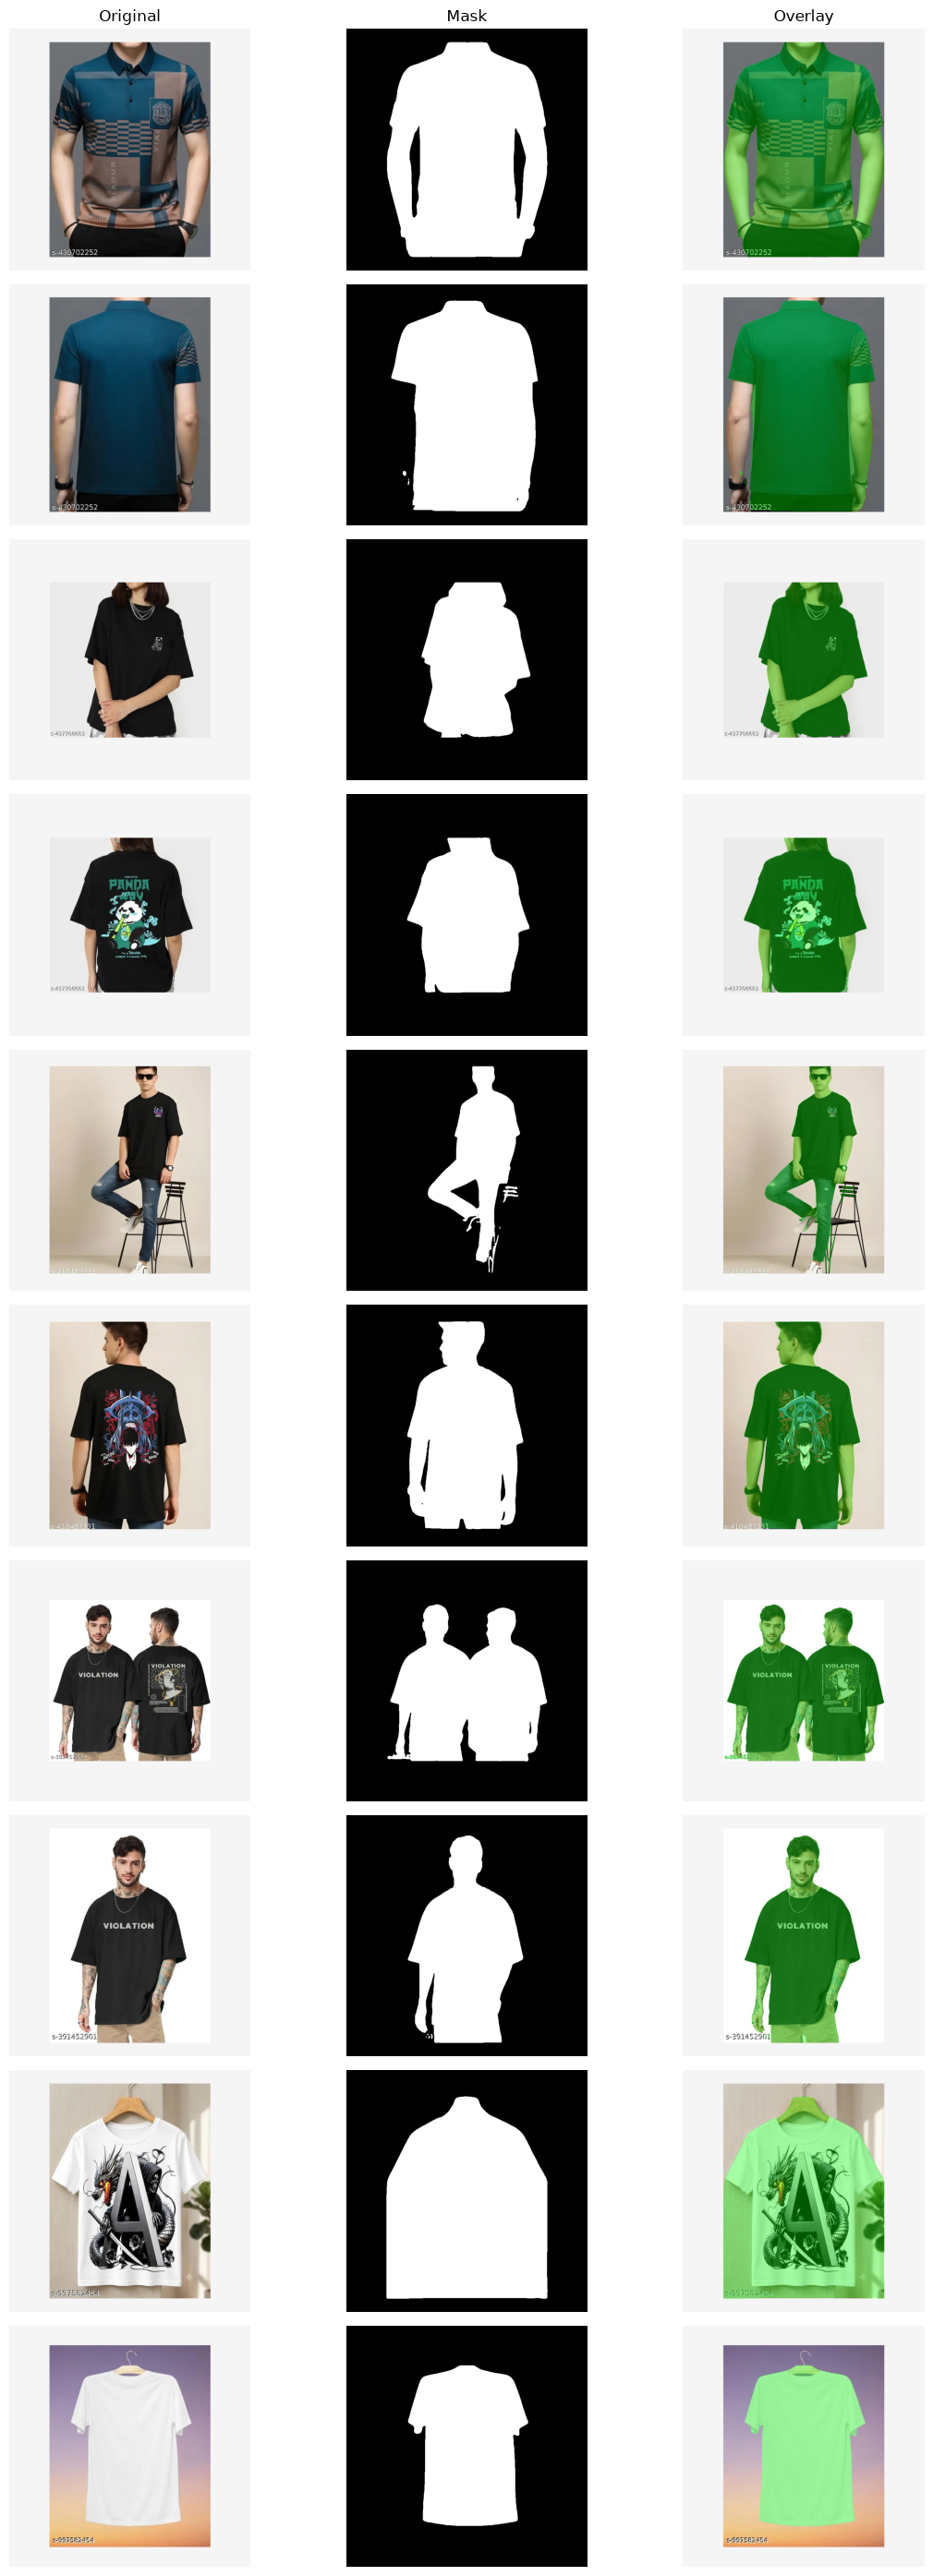

In [7]:
fig, axes = plt.subplots(10, 3, figsize=(12, 28))

for index in range(10):

    original = np.array(images[index])
    mask = np.array(masks[index])

    overlay = original.copy()
    selected = mask > 127

    overlay[selected] = (
        0.65 * overlay[selected] +
        0.35 * np.array([0, 255, 0])
    ).astype(np.uint8)

    axes[index, 0].imshow(original)
    axes[index, 1].imshow(mask, cmap="gray")
    axes[index, 2].imshow(overlay)

    axes[index, 0].set_ylabel(
        f"Set {image_metadata[index]['set_id']} "
        f"{image_metadata[index]['view']}"
    )

    for ax in axes[index]:
        ax.axis("off")

axes[0, 0].set_title("Original")
axes[0, 1].set_title("Mask")
axes[0, 2].set_title("Overlay")

plt.tight_layout()
plt.show()

In [8]:
import torchvision.models as models
import torchvision.transforms as transforms

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

dtype = torch.float16 if device.type == "cuda" else torch.float32

weights = models.ResNet18_Weights.DEFAULT
cnn = models.resnet18(weights=weights)

cnn.fc = torch.nn.Identity()
cnn = cnn.to(device)
cnn.eval()

preprocess = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("Device:", device)
print("ResNet18 feature extractor loaded.")

Device: cuda
ResNet18 feature extractor loaded.


In [9]:
layer_activations = []

hook = cnn.layer4.register_forward_hook(
    lambda module, inputs, output:
        layer_activations.append(output.detach().cpu())
)

cnn_features = []

with torch.no_grad():
    for index, image in enumerate(images):

        tensor = preprocess(image).unsqueeze(0).to(device)
        feature = cnn(tensor)

        cnn_features.append(feature.squeeze(0).cpu().numpy())

hook.remove()

cnn_features = np.array(cnn_features)

print("CNN feature shape:", cnn_features.shape)
print("Expected shape: (10, 512)")

CNN feature shape: (10, 512)
Expected shape: (10, 512)


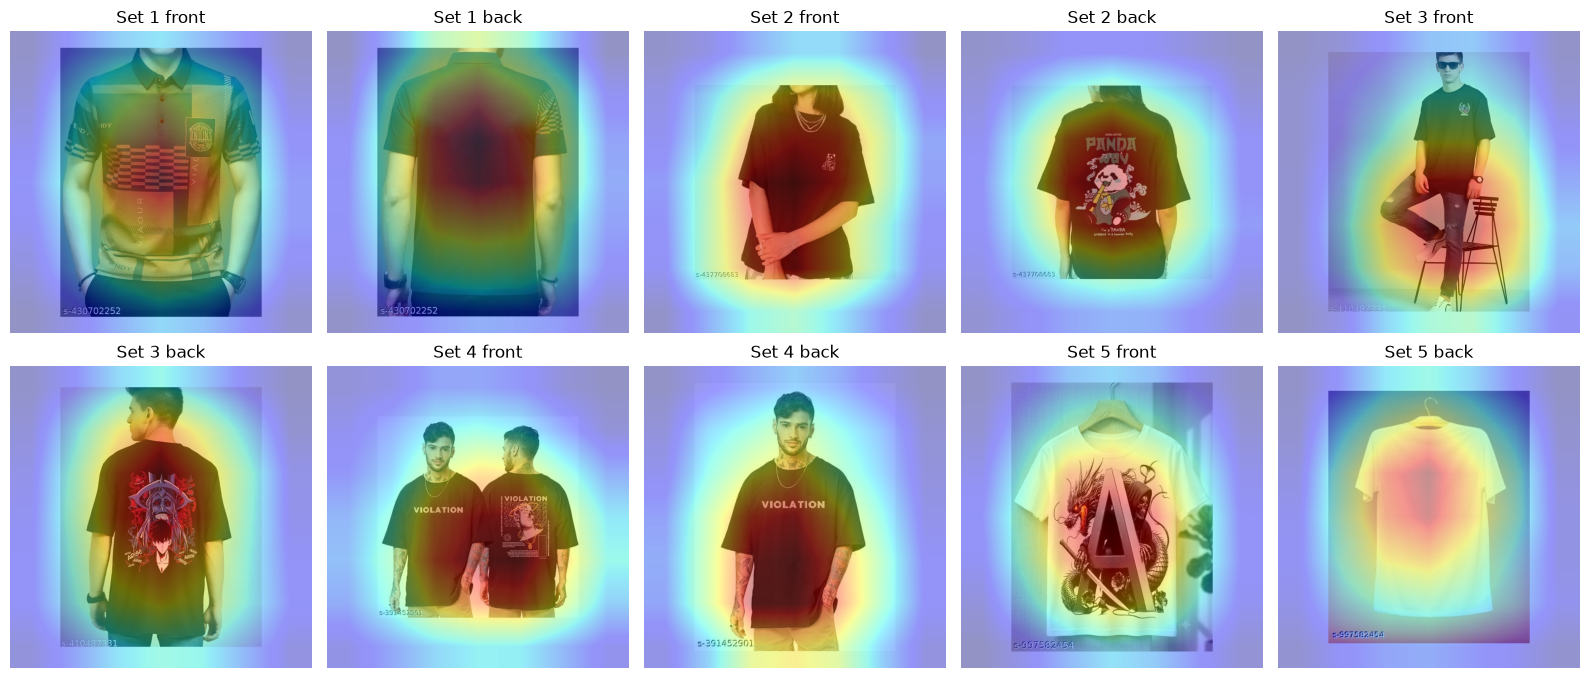

In [10]:
fig, axes = plt.subplots(2, 5, figsize=(16, 7))

for index, ax in enumerate(axes.flat):

    activation = layer_activations[index][0]
    heatmap = activation.mean(dim=0).numpy()

    heatmap = cv2.resize(
        heatmap, (IMAGE_SIZE, IMAGE_SIZE)
    )

    heatmap = (
        (heatmap - heatmap.min()) /
        (heatmap.max() - heatmap.min() + 1e-8)
    )

    ax.imshow(images[index])
    ax.imshow(heatmap, cmap="jet", alpha=0.4)
    ax.set_title(
        f"Set {image_metadata[index]['set_id']} "
        f"{image_metadata[index]['view']}"
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

In [11]:
color_features = []

for index, image in enumerate(images):

    image_array = np.array(image)
    mask_array = np.array(masks[index])

    histogram_parts = []

    for channel in range(3):

        histogram = cv2.calcHist(
            [image_array],
            [channel],
            mask_array,
            [4],
            [0, 256]
        ).flatten()

        histogram = histogram / (histogram.sum() + 1e-8)
        histogram_parts.extend(histogram)

    color_features.append(histogram_parts)

color_features = np.array(color_features)

print("Colour feature shape:", color_features.shape)
print("Expected shape: (10, 12)")

Colour feature shape: (10, 12)
Expected shape: (10, 12)


In [12]:
color_bipolar = np.where(color_features >= 0.25, 1, -1)
cnn_bipolar = np.where(cnn_features >= 0, 1, -1)

bam_weights = np.zeros(
    (color_bipolar.shape[1], cnn_bipolar.shape[1])
)

for index in range(10):
    bam_weights += np.outer(
        color_bipolar[index],
        cnn_bipolar[index]
    )

bam_scores_by_set = {}
selected_reference_by_set = {}

for set_id in range(1, 6):

    front_index = (set_id - 1) * 2
    back_index = front_index + 1

    candidate_indices = [front_index, back_index]
    scores = []

    for candidate_index in candidate_indices:

        recalled = np.sign(
            color_bipolar[candidate_index] @ bam_weights
        )

        score = float(
            np.mean(recalled == cnn_bipolar[candidate_index])
        )

        scores.append(score)

    bam_scores_by_set[set_id] = scores
    selected_reference_by_set[set_id] = candidate_indices[
        int(np.argmax(scores))
    ]

    print(f"Set {set_id}: diagnostic scores = {scores}")

Set 1: diagnostic scores = [1.0, 1.0]
Set 2: diagnostic scores = [1.0, 1.0]
Set 3: diagnostic scores = [1.0, 1.0]
Set 4: diagnostic scores = [1.0, 1.0]
Set 5: diagnostic scores = [0.0, 1.0]


In [13]:
from diffusers import StableDiffusionXLInpaintPipeline

MODEL_ID = "diffusers/stable-diffusion-xl-1.0-inpainting-0.1"

inpaint_pipe = StableDiffusionXLInpaintPipeline.from_pretrained(
    MODEL_ID,
    torch_dtype=dtype,
    use_safetensors=True
)

if device.type == "cuda":
    inpaint_pipe.enable_model_cpu_offload()
else:
    inpaint_pipe = inpaint_pipe.to(device)

if hasattr(inpaint_pipe, "enable_attention_slicing"):
    inpaint_pipe.enable_attention_slicing()

if hasattr(inpaint_pipe, "enable_vae_slicing"):
    inpaint_pipe.enable_vae_slicing()

if hasattr(inpaint_pipe, "enable_vae_tiling"):
    inpaint_pipe.enable_vae_tiling()

print("SDXL inpainting pipeline ready.")

C:\Users\admin\gpu_env\Lib\site-packages\diffusers\utils\deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)
Loading pipeline components...: 100%|██████████| 7/7 [00:07<00:00,  1.13s/it]

SDXL inpainting pipeline ready.


In [14]:
design_prompts = [
    (
        "modern streetwear T-shirt design, red and black geometric "
        "graphics, professional apparel product photography, "
        "preserve the original garment silhouette and view"
    ),
    (
        "minimal premium T-shirt design, elegant black graphic details "
        "with red accent lines, modern fashion product photography, "
        "preserve the original neckline, sleeves and view"
    ),
    (
        "contemporary colour-block T-shirt design, red and black "
        "graphic panels, balanced modern fashion design, "
        "preserve the original garment silhouette and view"
    )
]

negative_prompt = (
    "distorted neckline, malformed garment, extra sleeves, "
    "duplicate shirt, watermark, blurry, low quality, "
    "unwanted text, distorted body"
)

DESIGNS_PER_SET = 3
STEPS = 20
SEED = 42

print("Design variations:", len(design_prompts))

Design variations: 3


In [17]:
PRODUCTS = {
    1: {"name": "Teal geometric polo"},
    2: {"name": "Sky Magic black boxy T-shirt"},
    3: {"name": "Featous oversized graphic T-shirt"},
    4: {"name": "Black oversized printed T-shirt"},
    5: {"name": "Alphabet A snake-print kids T-shirt"}
}

print("Product configuration loaded:", len(PRODUCTS), "sets")

Product configuration loaded: 5 sets


In [25]:
GENERATE_SET_IDS = [2]  # Change to [1, 2, 3, 4, 5] after testing

generation_log = []

for set_id in GENERATE_SET_IDS:

    for design_id, design_prompt in enumerate(
        design_prompts, start=1
    ):

        for view in ["front", "back"]:

            image_index = (set_id - 1) * 2

            if view == "back":
                image_index += 1

            prompt = (
                f"{design_prompt}. "
                f"Product type: {PRODUCTS[set_id]['name']}. "
                f"View: {view}. "
                "Use the supplied product image as the reference. "
                "Preserve the shirt structure and product composition."
            )

            seed_value = (
                SEED + set_id * 100 +
                design_id * 10 +
                (1 if view == "back" else 0)
            )

            generator = torch.Generator(
                device="cuda" if device.type == "cuda" else "cpu"
            ).manual_seed(seed_value)

            result = inpaint_pipe(
                prompt=prompt,
                negative_prompt=negative_prompt,
                image=images[image_index],
                mask_image=masks[image_index],
                height=IMAGE_SIZE,
                width=IMAGE_SIZE,
                num_inference_steps=STEPS,
                guidance_scale=7.0,
                strength=0.65,
                generator=generator
            )

            generated_image = result.images[0]

            output_folder = (
                OUTPUT_DIR /
                f"set_{set_id}" /
                f"design_{design_id}"
            )

            output_folder.mkdir(parents=True, exist_ok=True)

            output_path = output_folder / f"{view}.png"
            generated_image.save(output_path)

            generation_log.append({
                "set_id": set_id,
                "product": PRODUCTS[set_id]["name"],
                "design_id": design_id,
                "view": view,
                "source_path": image_metadata[image_index]["path"],
                "bam_scores": str(bam_scores_by_set[set_id]),
                "prompt": prompt,
                "seed": seed_value,
                "steps": STEPS,
                "output_path": str(output_path)
            })

            print(
                f"Generated: Set {set_id}, "
                f"Design {design_id}, {view}"
            )

generation_df = pd.DataFrame(generation_log)

print("\nImages generated:", len(generation_df))

100%|██████████| 13/13 [00:04<00:00,  2.67it/s]


Generated: Set 2, Design 1, front


100%|██████████| 13/13 [00:04<00:00,  2.85it/s]


Generated: Set 2, Design 1, back


100%|██████████| 13/13 [00:04<00:00,  2.90it/s]


...

Generated: Set 2, Design 2, back


100%|██████████| 13/13 [00:04<00:00,  2.90it/s]


Generated: Set 2, Design 3, front


100%|██████████| 13/13 [00:04<00:00,  2.90it/s]


Generated: Set 2, Design 3, back

Images generated: 6


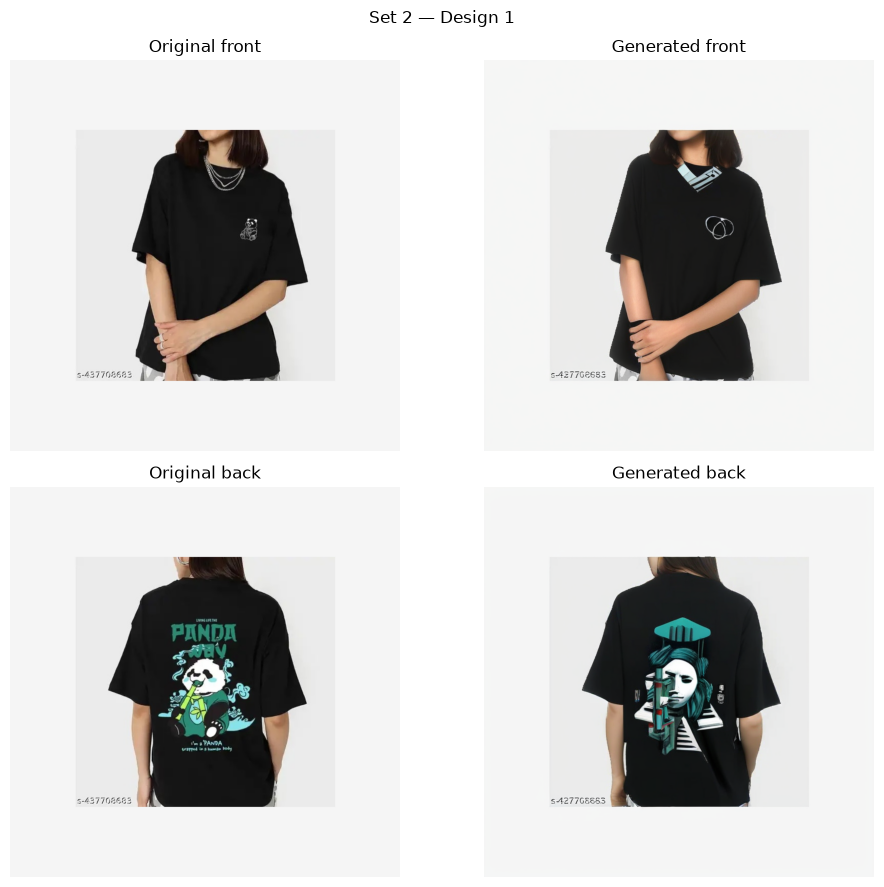

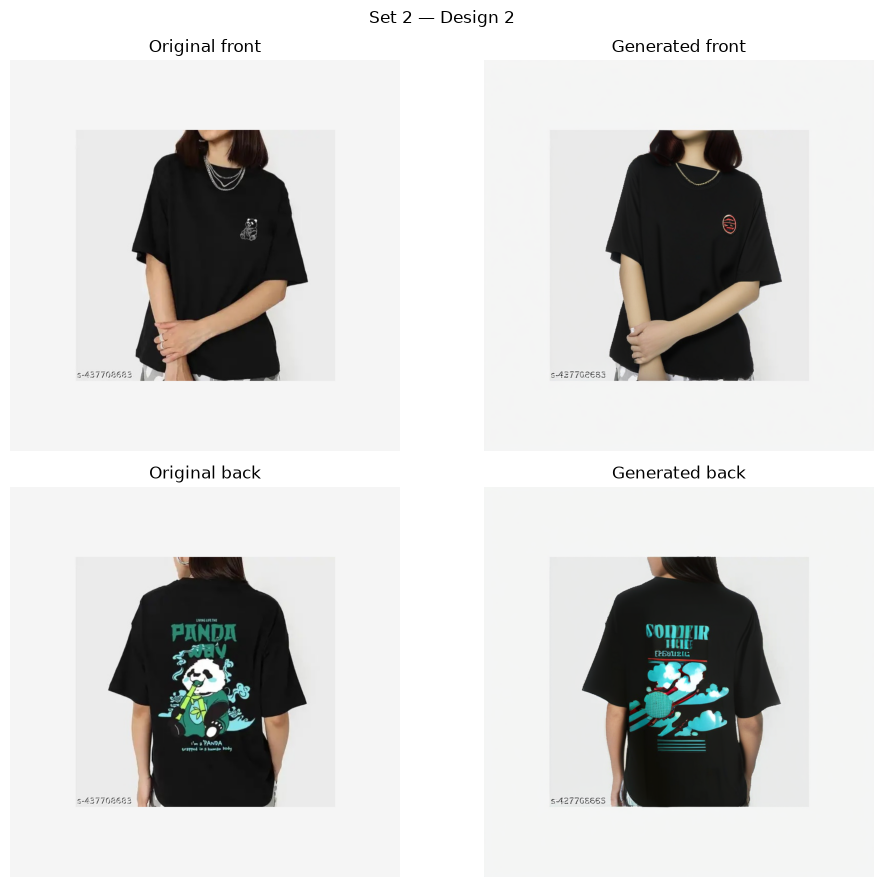

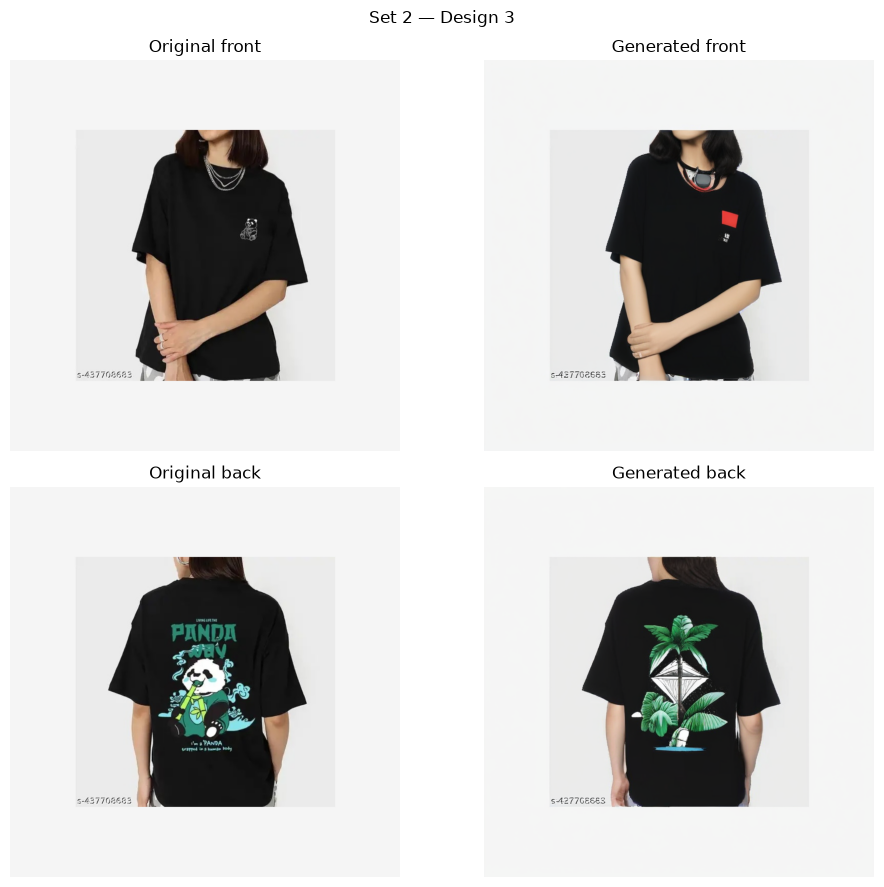

In [26]:
for set_id in GENERATE_SET_IDS:

    for design_id in range(1, DESIGNS_PER_SET + 1):

        fig, axes = plt.subplots(2, 2, figsize=(10, 9))

        for row, view in enumerate(["front", "back"]):

            source_index = (set_id - 1) * 2 + row

            result_row = generation_df[
                (generation_df["set_id"] == set_id) &
                (generation_df["design_id"] == design_id) &
                (generation_df["view"] == view)
            ].iloc[0]

            axes[row, 0].imshow(images[source_index])
            axes[row, 0].set_title(f"Original {view}")

            axes[row, 1].imshow(
                Image.open(result_row["output_path"])
            )
            axes[row, 1].set_title(f"Generated {view}")

            axes[row, 0].axis("off")
            axes[row, 1].axis("off")

        plt.suptitle(f"Set {set_id} — Design {design_id}")
        plt.tight_layout()
        plt.show()

In [27]:
pd.DataFrame(image_metadata).to_csv(
    OUTPUT_DIR / "source_image_audit.csv",
    index=False
)

generation_df.to_csv(
    OUTPUT_DIR / "generation_audit.csv",
    index=False
)

if not generation_df.empty:

    summary_df = generation_df.groupby(
        ["set_id", "product", "design_id"]
    ).agg(
        images_generated=("output_path", "count")
    ).reset_index()

    summary_df.to_csv(
        OUTPUT_DIR / "generation_summary.csv",
        index=False
    )

    print(summary_df)

print("\nAudit files saved in:", OUTPUT_DIR.resolve())

   set_id                       product  design_id  images_generated
0       2  Sky Magic black boxy T-shirt          1                 2
1       2  Sky Magic black boxy T-shirt          2                 2
2       2  Sky Magic black boxy T-shirt          3                 2

Audit files saved in: C:\Users\admin\Documents\ann_ajay_project\generated_designs


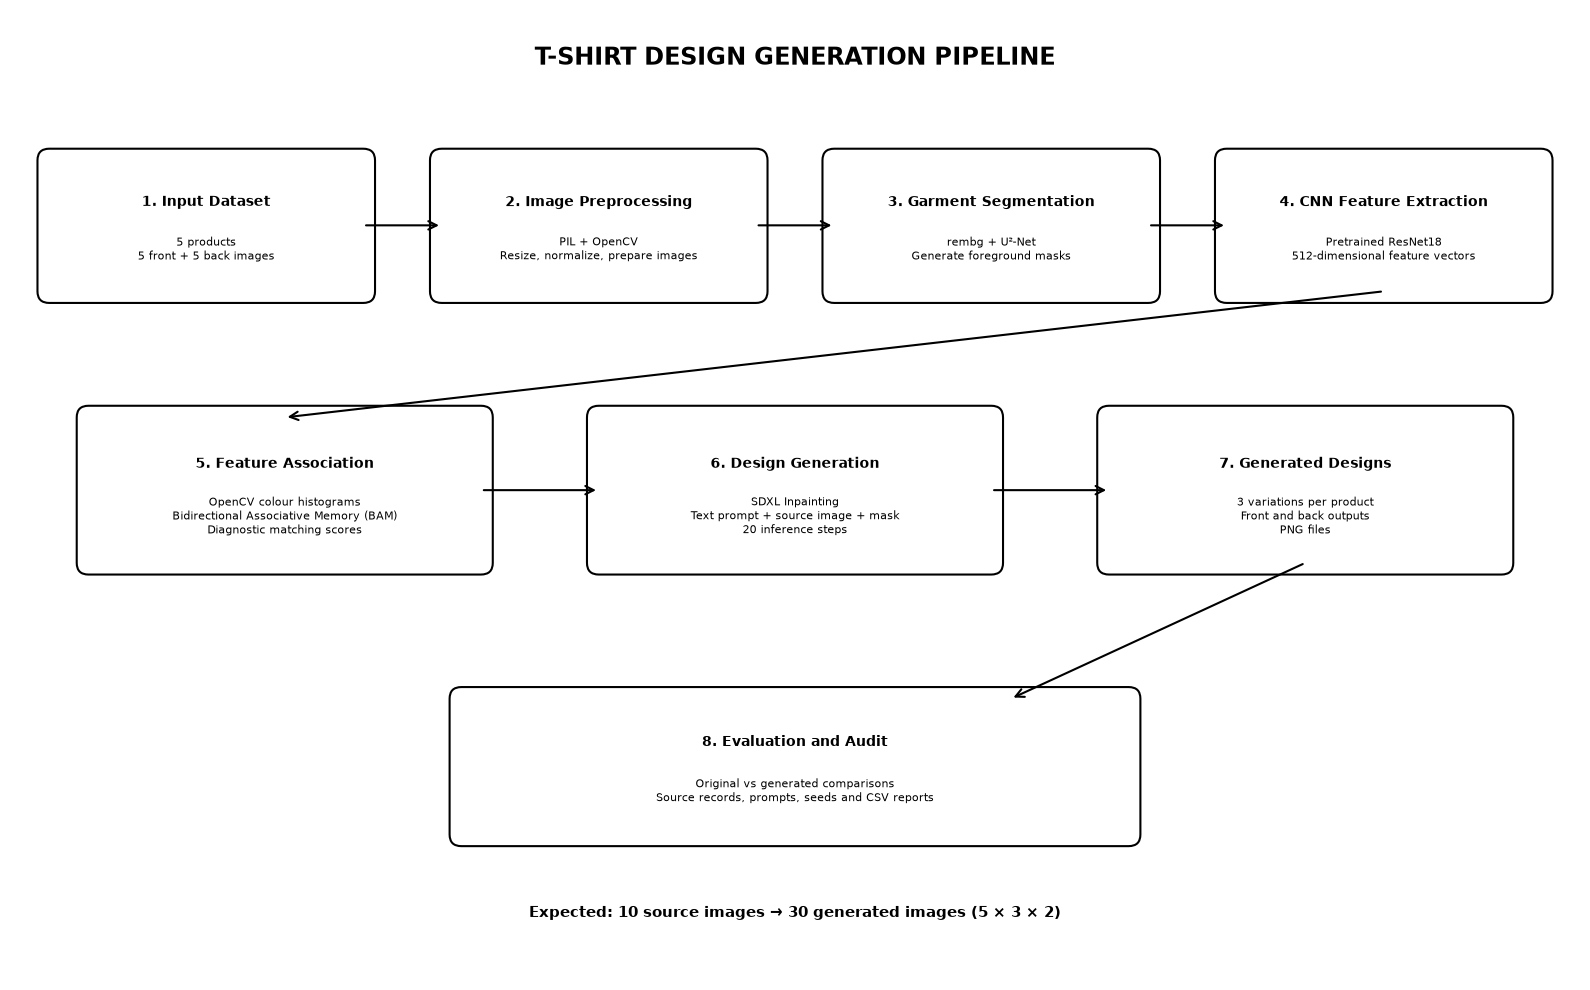

In [28]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

fig, ax = plt.subplots(figsize=(16, 10))

ax.set_xlim(0, 16)
ax.set_ylim(0, 10)
ax.axis("off")

def add_box(x, y, width, height, title, details):
    box = FancyBboxPatch(
        (x, y), width, height,
        boxstyle="round,pad=0.12",
        linewidth=1.5,
        edgecolor="black",
        facecolor="white"
    )
    ax.add_patch(box)

    ax.text(
        x + width / 2, y + height * 0.68,
        title,
        ha="center", va="center",
        fontsize=10, fontweight="bold"
    )

    ax.text(
        x + width / 2, y + height * 0.32,
        details,
        ha="center", va="center",
        fontsize=8,
        wrap=True
    )

def add_arrow(x1, y1, x2, y2):
    arrow = FancyArrowPatch(
        (x1, y1), (x2, y2),
        arrowstyle="->",
        mutation_scale=15,
        linewidth=1.5,
        color="black"
    )
    ax.add_patch(arrow)

ax.text(
    8, 9.5,
    "T-SHIRT DESIGN GENERATION PIPELINE",
    ha="center", va="center",
    fontsize=17, fontweight="bold"
)

# First row
add_box(
    0.4, 7.1, 3.2, 1.35,
    "1. Input Dataset",
    "5 products\n5 front + 5 back images"
)

add_box(
    4.4, 7.1, 3.2, 1.35,
    "2. Image Preprocessing",
    "PIL + OpenCV\nResize, normalize, prepare images"
)

add_box(
    8.4, 7.1, 3.2, 1.35,
    "3. Garment Segmentation",
    "rembg + U²-Net\nGenerate foreground masks"
)

add_box(
    12.4, 7.1, 3.2, 1.35,
    "4. CNN Feature Extraction",
    "Pretrained ResNet18\n512-dimensional feature vectors"
)

add_arrow(3.6, 7.78, 4.4, 7.78)
add_arrow(7.6, 7.78, 8.4, 7.78)
add_arrow(11.6, 7.78, 12.4, 7.78)

# Second row
add_box(
    0.8, 4.3, 4.0, 1.5,
    "5. Feature Association",
    "OpenCV colour histograms\nBidirectional Associative Memory (BAM)\nDiagnostic matching scores"
)

add_box(
    6.0, 4.3, 4.0, 1.5,
    "6. Design Generation",
    "SDXL Inpainting\nText prompt + source image + mask\n20 inference steps"
)

add_box(
    11.2, 4.3, 4.0, 1.5,
    "7. Generated Designs",
    "3 variations per product\nFront and back outputs\nPNG files"
)

add_arrow(14.0, 7.1, 2.8, 5.8)
add_arrow(4.8, 5.05, 6.0, 5.05)
add_arrow(10.0, 5.05, 11.2, 5.05)

# Final output
add_box(
    4.6, 1.5, 6.8, 1.4,
    "8. Evaluation and Audit",
    "Original vs generated comparisons\nSource records, prompts, seeds and CSV reports"
)

add_arrow(13.2, 4.3, 10.2, 2.9)

ax.text(
    8, 0.65,
    "Expected: 10 source images → 30 generated images (5 × 3 × 2)",
    ha="center", fontsize=11, fontweight="bold"
)

plt.tight_layout()
plt.show()

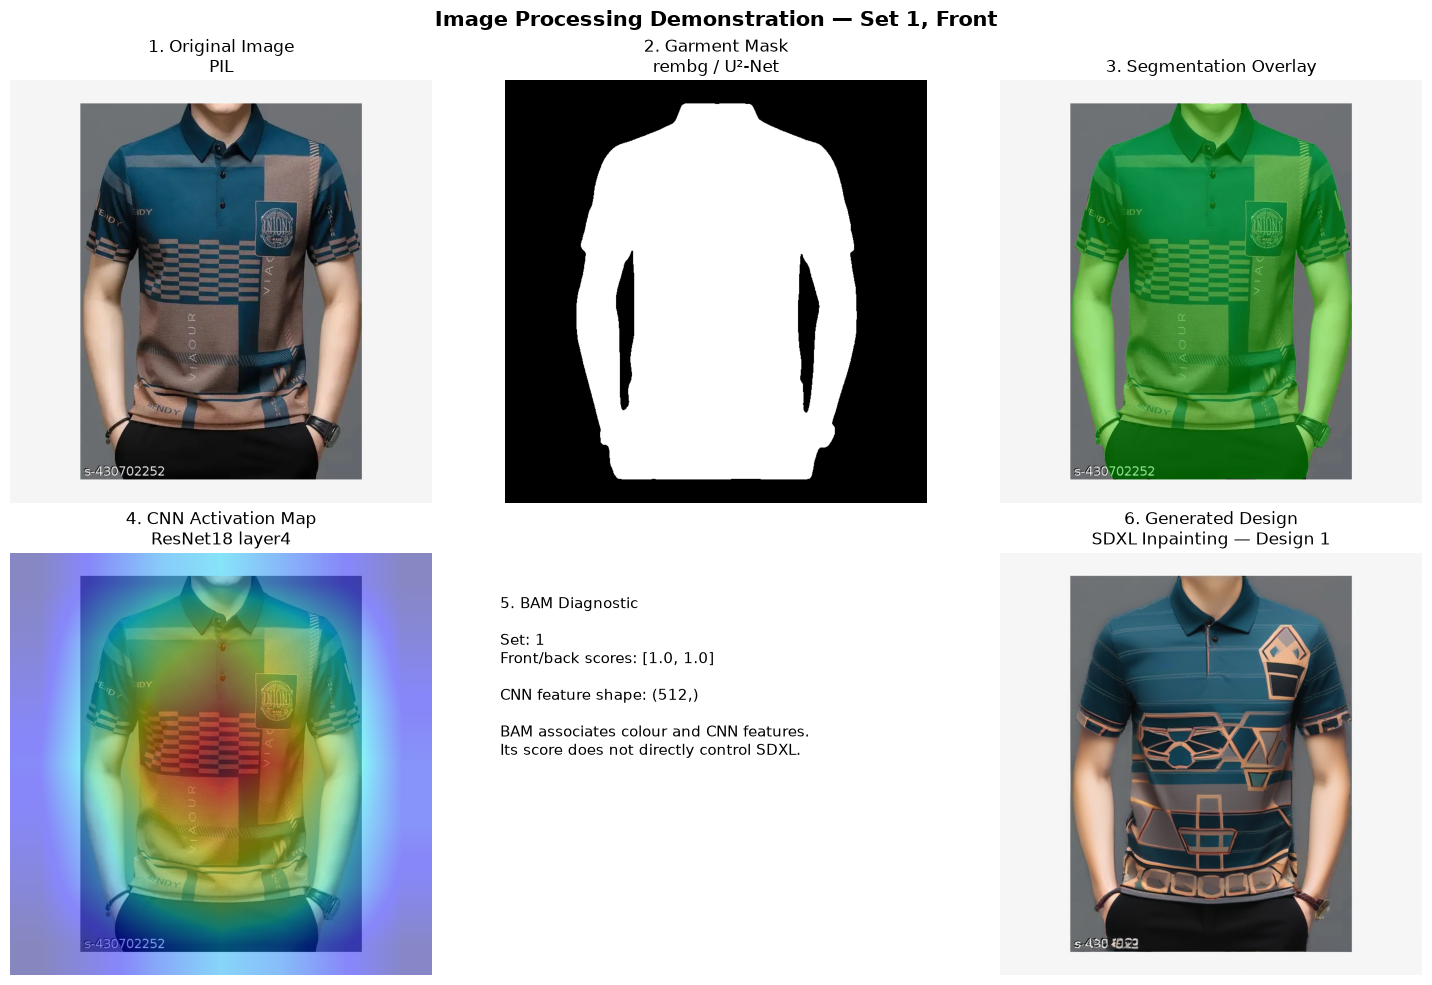

PROCESSING SUMMARY
------------------
Input: (768, 768) RGB image
Segmentation: rembg using U²-Net
CNN: Pretrained ResNet18
CNN feature dimensions: (512,)
Association: Colour histogram + BAM
Generator: Stable Diffusion XL Inpainting
Prompt design: 1
Generated output: generated_designs\set_1\design_1\front.png


In [29]:
import matplotlib.pyplot as plt
import numpy as np
import cv2
from PIL import Image
from pathlib import Path

# Select the product and view to demonstrate
SET_ID = 1
VIEW = "front"
DESIGN_ID = 1

# Images are ordered: Set 1 front, Set 1 back, Set 2 front, ...
IMAGE_INDEX = (SET_ID - 1) * 2

if VIEW == "back":
    IMAGE_INDEX += 1

# Check that processing results exist
required_variables = [
    "images",
    "masks",
    "layer_activations",
    "cnn_features",
    "bam_scores_by_set"
]

missing_variables = [
    name for name in required_variables
    if name not in globals()
]

if missing_variables:
    raise NameError(
        "Run the relevant preprocessing/CNN/BAM cells first. "
        "Missing: " + ", ".join(missing_variables)
    )

# Retrieve original image and mask
original = images[IMAGE_INDEX]
mask = np.array(masks[IMAGE_INDEX])

# Create segmentation overlay
original_array = np.array(original)
overlay = original_array.copy()

selected = mask > 127
overlay[selected] = (
    0.65 * overlay[selected] +
    0.35 * np.array([0, 255, 0])
).astype(np.uint8)

# Retrieve CNN activation map
activation = layer_activations[IMAGE_INDEX][0]
heatmap = activation.mean(dim=0).numpy()

heatmap = cv2.resize(
    heatmap,
    (original.width, original.height)
)

heatmap = (
    (heatmap - heatmap.min()) /
    (heatmap.max() - heatmap.min() + 1e-8)
)

# Retrieve BAM diagnostic score
set_scores = bam_scores_by_set[SET_ID]

# Find the generated image if the generation cell has run
generated_path = None

if "generation_df" in globals() and not generation_df.empty:

    matching_rows = generation_df[
        (generation_df["set_id"] == SET_ID) &
        (generation_df["design_id"] == DESIGN_ID) &
        (generation_df["view"] == VIEW)
    ]

    if not matching_rows.empty:
        generated_path = Path(
            matching_rows.iloc[0]["output_path"]
        )

# Also check the standard output folder
if generated_path is None:
    candidate = (
        Path("generated_designs") /
        f"set_{SET_ID}" /
        f"design_{DESIGN_ID}" /
        f"{VIEW}.png"
    )

    if candidate.exists():
        generated_path = candidate

# Create the demonstration
fig, axes = plt.subplots(2, 3, figsize=(15, 10))

axes[0, 0].imshow(original)
axes[0, 0].set_title("1. Original Image\nPIL")

axes[0, 1].imshow(mask, cmap="gray")
axes[0, 1].set_title("2. Garment Mask\nrembg / U²-Net")

axes[0, 2].imshow(overlay)
axes[0, 2].set_title("3. Segmentation Overlay")

axes[1, 0].imshow(original)
axes[1, 0].imshow(heatmap, cmap="jet", alpha=0.45)
axes[1, 0].set_title("4. CNN Activation Map\nResNet18 layer4")

axes[1, 1].axis("off")
axes[1, 1].text(
    0.05, 0.9,
    "5. BAM Diagnostic\n\n"
    f"Set: {SET_ID}\n"
    f"Front/back scores: {set_scores}\n\n"
    f"CNN feature shape: {cnn_features[IMAGE_INDEX].shape}\n\n"
    "BAM associates colour and CNN features.\n"
    "Its score does not directly control SDXL.",
    va="top",
    fontsize=11,
    wrap=True
)

if generated_path is not None and generated_path.exists():
    axes[1, 2].imshow(Image.open(generated_path))
    axes[1, 2].set_title(
        f"6. Generated Design\nSDXL Inpainting — Design {DESIGN_ID}"
    )
else:
    axes[1, 2].axis("off")
    axes[1, 2].text(
        0.5, 0.5,
        "Generated image not found.\n"
        "Run the SDXL generation cell first.",
        ha="center", va="center",
        wrap=True
    )

for ax in axes.flat:
    ax.axis("off") if ax.images else None

plt.suptitle(
    f"Image Processing Demonstration — Set {SET_ID}, {VIEW.title()}",
    fontsize=15,
    fontweight="bold"
)
plt.tight_layout()
plt.show()

print("PROCESSING SUMMARY")
print("------------------")
print("Input:", original.size, "RGB image")
print("Segmentation:", "rembg using U²-Net")
print("CNN:", "Pretrained ResNet18")
print("CNN feature dimensions:", cnn_features[IMAGE_INDEX].shape)
print("Association:", "Colour histogram + BAM")
print("Generator:", "Stable Diffusion XL Inpainting")
print("Prompt design:", DESIGN_ID)
print("Generated output:", generated_path)

T-SHIRT DESIGN GENERATION — COMPLETE MODEL EXPLANATION

1. INPUT DATASET
------------------------------------------------------------------------------------------
Input             : 5 T-shirt product sets
Images per set    : 1 front + 1 back
Total input       : 10 images
Image source      : Meesho product galleries
Image format      : RGB
Processing size   : 768 x 768 pixels

2. IMAGE PREPROCESSING
------------------------------------------------------------------------------------------
Libraries         : PIL, NumPy, OpenCV
Operations        : RGB conversion, resizing, padding
Purpose           : Standardize dimensions and pixel format
Segmentation      : rembg with U²-Net
Output            : Grayscale foreground mask
Mask use          : Identify regions SDXL is allowed to modify

3. CNN FEATURE EXTRACTION
------------------------------------------------------------------------------------------
Architecture      : ResNet18
Library           : torchvision
Pretrained weights: ResNet

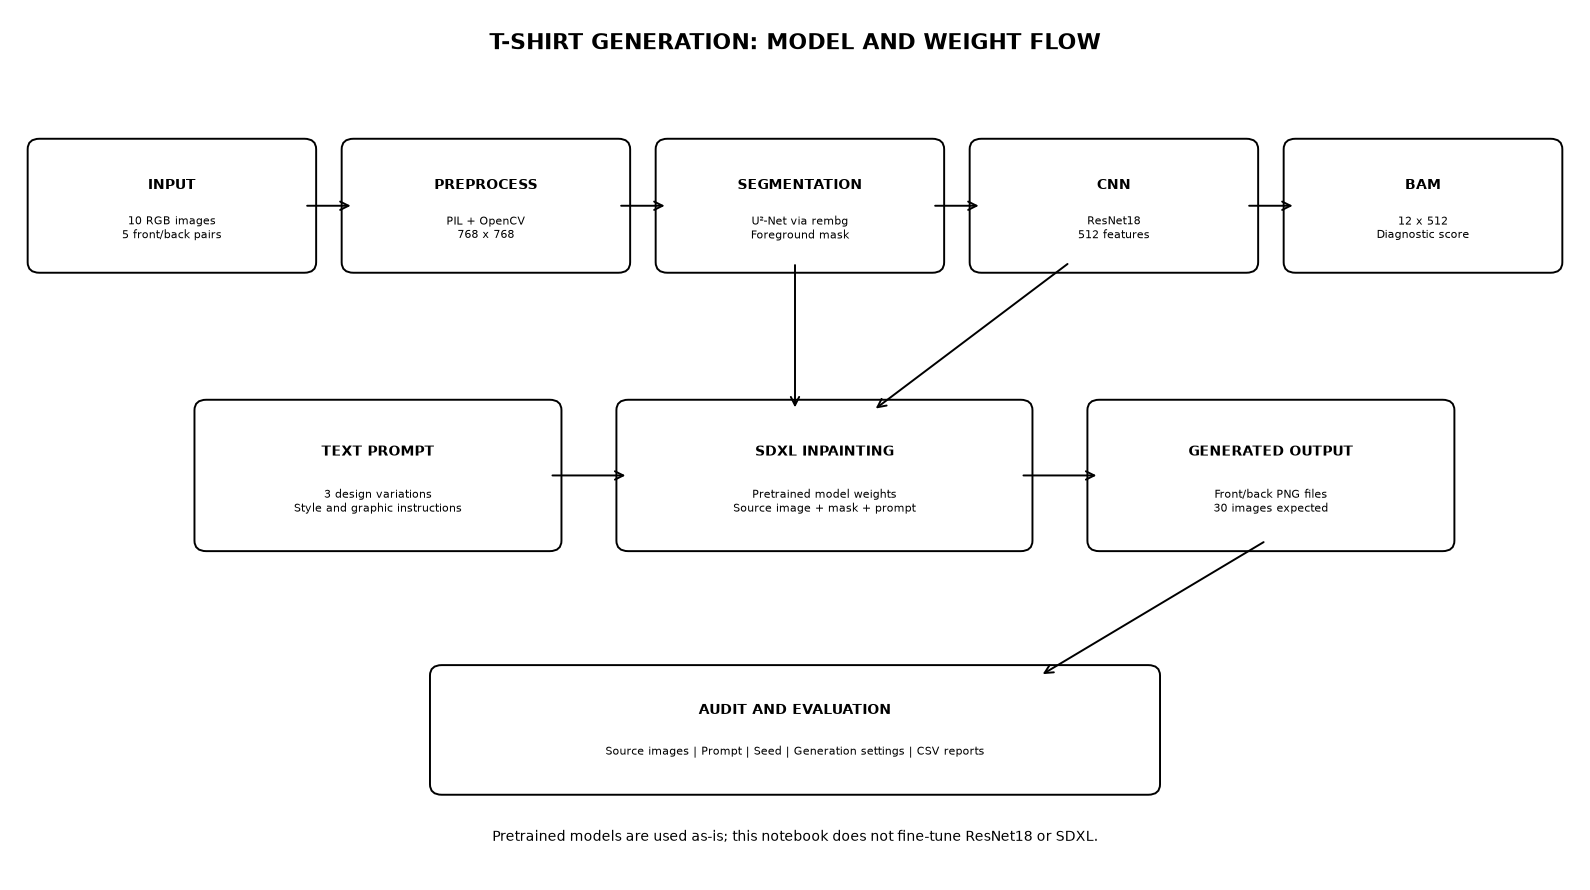


EXPLANATION COMPLETE


In [30]:
import torch
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

# --------------------------------------------------
# 1. PROJECT CONFIGURATION
# --------------------------------------------------

print("=" * 90)
print("T-SHIRT DESIGN GENERATION — COMPLETE MODEL EXPLANATION")
print("=" * 90)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("\n1. INPUT DATASET")
print("-" * 90)
print("Input             : 5 T-shirt product sets")
print("Images per set    : 1 front + 1 back")
print("Total input       : 10 images")
print("Image source      : Meesho product galleries")
print("Image format      : RGB")
print("Processing size   : 768 x 768 pixels")

print("\n2. IMAGE PREPROCESSING")
print("-" * 90)
print("Libraries         : PIL, NumPy, OpenCV")
print("Operations        : RGB conversion, resizing, padding")
print("Purpose           : Standardize dimensions and pixel format")
print("Segmentation      : rembg with U²-Net")
print("Output            : Grayscale foreground mask")
print("Mask use          : Identify regions SDXL is allowed to modify")

# --------------------------------------------------
# 2. CNN MODEL AND WEIGHTS
# --------------------------------------------------

print("\n3. CNN FEATURE EXTRACTION")
print("-" * 90)
print("Architecture      : ResNet18")
print("Library           : torchvision")
print("Pretrained weights: ResNet18_Weights.DEFAULT")
print("Weight source     : ImageNet-pretrained weights")
print("Input size        : 224 x 224 pixels")
print("Feature output    : 512 values per image")
print("Classification head: Replaced with Identity()")
print("Training          : No fine-tuning in this notebook")
print("Purpose           : Extract visual features such as shapes,")
print("                    textures and appearance patterns")

if "cnn" in globals():
    print("Actual CNN device :", next(cnn.parameters()).device)
    print("CNN in evaluation :", not cnn.training)

if "cnn_features" in globals():
    print("Actual feature matrix:", cnn_features.shape)

# --------------------------------------------------
# 3. COLOUR FEATURES AND BAM
# --------------------------------------------------

print("\n4. COLOUR FEATURES + BAM ASSOCIATIVE MEMORY")
print("-" * 90)
print("Colour extraction : OpenCV colour histograms")
print("Histogram bins    : 4 bins per RGB channel")
print("Colour vector     : 12 values per image")
print("CNN vector        : 512 values per image")
print("BAM architecture  : Bidirectional Associative Memory")
print("Weight matrix     : 12 x 512")
print("Weight construction: Sum of outer products of bipolar vectors")
print("Purpose           : Demonstrate association between colour")
print("                    and CNN features")
print("Limitation        : Experimental diagnostic memory; only 10 images")
print("Important         : BAM scores do not directly control SDXL")

if "bam_weights" in globals():
    print("Actual BAM weight shape:", bam_weights.shape)

if "bam_scores_by_set" in globals():
    print("BAM scores available for sets:", list(bam_scores_by_set.keys()))

# --------------------------------------------------
# 4. GENERATIVE MODEL AND WEIGHTS
# --------------------------------------------------

print("\n5. IMAGE GENERATION")
print("-" * 90)
print("Model             : Stable Diffusion XL Inpainting")
print("Model ID          : diffusers/stable-diffusion-xl-1.0-inpainting-0.1")
print("Library           : Hugging Face Diffusers")
print("Model weights     : Pretrained SDXL inpainting checkpoint")
print("Fine-tuning       : Not performed in this notebook")
print("Conditioning      : Source image + mask + text prompt")
print("Inference steps   : 20")
print("Guidance scale    : 7.0")
print("Strength          : 0.65")
print("Image size        : 768 x 768")
print("Seed              : Set-specific deterministic seed")
print("Output format     : PNG")
print("Design variations : 3 per product")
print("Generated images  : 5 products x 3 designs x 2 views = 30")

if "inpaint_pipe" in globals():
    print("Pipeline class    :", type(inpaint_pipe).__name__)
    print("Pipeline device   :", device)

# --------------------------------------------------
# 5. ACTUAL INPUT-TO-OUTPUT FLOW
# --------------------------------------------------

print("\n6. COMPLETE DATA FLOW")
print("-" * 90)

workflow_steps = [
    ("INPUT", "10 front/back images"),
    ("PREPROCESS", "RGB + resize + padding"),
    ("SEGMENT", "rembg / U²-Net mask"),
    ("CNN", "ResNet18 pretrained features"),
    ("BAM", "Colour-CNN association score"),
    ("PROMPT", "Choose one of 3 design prompts"),
    ("SDXL", "Image + mask + prompt -> inpainting"),
    ("OUTPUT", "Generated front/back PNG"),
    ("AUDIT", "Source, prompt, seed and output CSV")
]

for i, (stage, description) in enumerate(workflow_steps, start=1):
    print(f"{i:02d}. {stage:<12} -> {description}")

# --------------------------------------------------
# 6. OUTPUT AND AUDIT INFORMATION
# --------------------------------------------------

print("\n7. EXPECTED OUTPUTS")
print("-" * 90)
print("generated_designs/set_1/design_1/front.png")
print("generated_designs/set_1/design_1/back.png")
print("...")
print("generated_designs/set_5/design_3/front.png")
print("generated_designs/set_5/design_3/back.png")
print("generation_audit.csv")
print("generation_summary.csv")
print("source_image_audit.csv")

if "generation_df" in globals():
    print("\nActual generated output records:", len(generation_df))
else:
    print("\nActual generated output records: Generation cell not run yet.")

# --------------------------------------------------
# 7. VISUAL ARCHITECTURE DIAGRAM
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(16, 9))
ax.set_xlim(0, 16)
ax.set_ylim(0, 10)
ax.axis("off")

def add_model_box(x, y, width, height, title, details):
    box = FancyBboxPatch(
        (x, y), width, height,
        boxstyle="round,pad=0.12",
        edgecolor="black",
        facecolor="white",
        linewidth=1.4
    )
    ax.add_patch(box)

    ax.text(
        x + width / 2, y + height * 0.68,
        title, ha="center", va="center",
        fontsize=10, fontweight="bold"
    )

    ax.text(
        x + width / 2, y + height * 0.30,
        details, ha="center", va="center",
        fontsize=8, wrap=True
    )

def add_model_arrow(x1, y1, x2, y2):
    ax.add_patch(FancyArrowPatch(
        (x1, y1), (x2, y2),
        arrowstyle="->", mutation_scale=15,
        linewidth=1.4, color="black"
    ))

ax.text(
    8, 9.55,
    "T-SHIRT GENERATION: MODEL AND WEIGHT FLOW",
    ha="center", fontsize=16, fontweight="bold"
)

# Main processing row
boxes = [
    (0.3, 7.1, 2.7, 1.3, "INPUT", "10 RGB images\n5 front/back pairs"),
    (3.5, 7.1, 2.7, 1.3, "PREPROCESS", "PIL + OpenCV\n768 x 768"),
    (6.7, 7.1, 2.7, 1.3, "SEGMENTATION", "U²-Net via rembg\nForeground mask"),
    (9.9, 7.1, 2.7, 1.3, "CNN", "ResNet18\n512 features"),
    (13.1, 7.1, 2.6, 1.3, "BAM", "12 x 512\nDiagnostic score")
]

for box in boxes:
    add_model_box(*box)

for x in [3.0, 6.2, 9.4, 12.6]:
    add_model_arrow(x, 7.75, x + 0.5, 7.75)

# Generation row
add_model_box(
    2.0, 3.9, 3.5, 1.5,
    "TEXT PROMPT",
    "3 design variations\nStyle and graphic instructions"
)

add_model_box(
    6.3, 3.9, 4.0, 1.5,
    "SDXL INPAINTING",
    "Pretrained model weights\nSource image + mask + prompt"
)

add_model_box(
    11.1, 3.9, 3.5, 1.5,
    "GENERATED OUTPUT",
    "Front/back PNG files\n30 images expected"
)

add_model_arrow(5.5, 4.65, 6.3, 4.65)
add_model_arrow(10.3, 4.65, 11.1, 4.65)

# Source images and mask connect to generation
add_model_arrow(8.0, 7.1, 8.0, 5.4)
add_model_arrow(10.8, 7.1, 8.8, 5.4)

# Audit row
add_model_box(
    4.4, 1.1, 7.2, 1.25,
    "AUDIT AND EVALUATION",
    "Source images | Prompt | Seed | Generation settings | CSV reports"
)

add_model_arrow(12.8, 3.9, 10.5, 2.35)

ax.text(
    8, 0.45,
    "Pretrained models are used as-is; this notebook does not fine-tune ResNet18 or SDXL.",
    ha="center", fontsize=10
)

plt.tight_layout()
plt.show()

print("\nEXPLANATION COMPLETE")